# Chapter 7 — Support Vector Machines and Kernel Methods

> Reproduction notebook for **scikit-learn Cookbook, Third Edition** (John Sukup, Packt 2025).

## Chapter Summary

Real datasets rarely have neatly separable classes. **Support Vector Machines (SVMs)** find the boundary that separates classes with the **largest possible margin**, and **kernel functions** let them draw curved boundaries by mapping the data into a higher-dimensional space.

| Recipe | Key idea |
|---|---|
| Introduction to SVMs | Hyperplane + margin + support vectors; `SVC` (classification) and `SVR` (regression) |
| Kernel functions | `linear`, `poly`, `rbf` – the kernel trick avoids explicit high-dimensional coordinates |
| Tuning SVM parameters | `C`, `kernel`, `degree`, `gamma` with grid search + cross-validation |
| SVMs in high-dimensional spaces | Effective when features ≫ samples; visualise with PCA |
| Evaluating SVM models | Accuracy, precision, recall, F1, ROC curve and AUC |

## 1. Introduction to SVMs

**Theory.**

* A **hyperplane** is the decision boundary that divides feature space into regions, one per class (a line in 2D, a plane in 3D, ...).
* The **margin** is the distance between the hyperplane and the closest points of each class. Those closest points are the **support vectors** — only they define the boundary.
* The SVM chooses the hyperplane that **maximises the margin**, which reduces generalisation error.
* **Soft margin:** *slack variables* tolerate some misclassification (like loosening a taut rope), making the model robust to outliers and noise. The parameter `C` controls how strict this is.
* SVMs work for classification (`SVC`) and regression (`SVR`) and are effective when the number of features is large relative to the number of samples.

> Note: the book describes the hyperplane as "a non-linear line"; strictly speaking the hyperplane is *linear in the (possibly kernel-mapped) feature space* and appears curved when projected back to the original space.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [2]:
def styled_report(y_true, y_hat):
    rep = pd.DataFrame(classification_report(y_true, y_hat, output_dict=True)).transpose()
    return (rep.style
        .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

svm_classifier = SVC(kernel='linear')
svm_classifier.fit(X_train, y_train)
y_pred = svm_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
display(styled_report(y_test, y_pred))

Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


**SVM for regression (`SVR`).** For regression, lower MSE/MAE is better; how low is acceptable is a business question. (The book fits it on the first two Iris features purely as a demonstration — the target is a class index, so this is only illustrative.)

In [3]:
from sklearn.metrics import mean_squared_error

svm_regressor = SVR(kernel='rbf')
svm_regressor.fit(X_train[:, :2], y_train)
y_pred_reg = svm_regressor.predict(X_test[:, :2])

mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.2f}")

MSE: 0.20


**How it works — visualising SVM decision boundaries.** The book builds a mesh grid and plots with `DecisionBoundaryDisplay`; its example passes the regressor, which draws a smooth *prediction surface*. Below I draw both: the regressor's surface (as in the book) and a proper classification boundary from an `SVC` trained on the same two features.

/usr/local/lib/python3.13/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


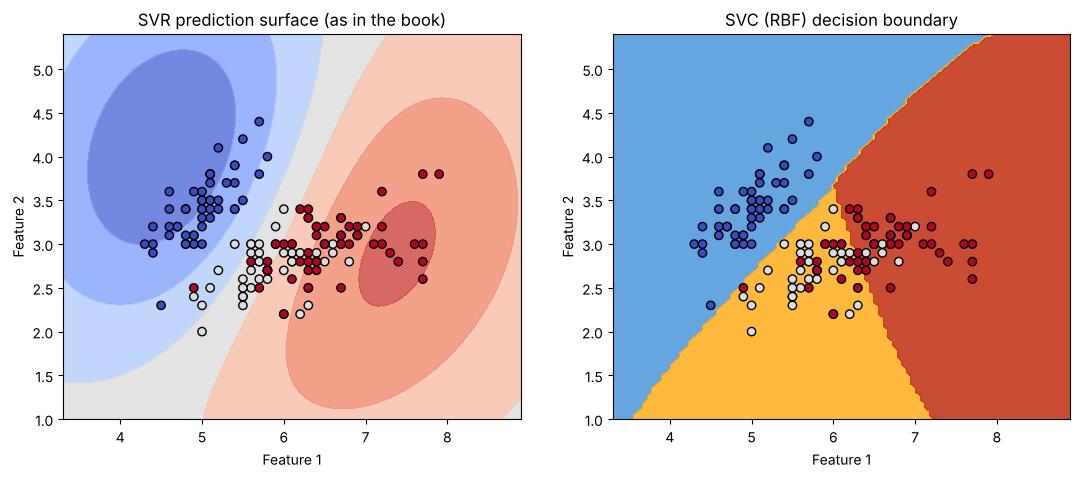

In [4]:
from sklearn.inspection import DecisionBoundaryDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# (a) the book's version: SVR prediction surface over the first two features
DecisionBoundaryDisplay.from_estimator(
    svm_regressor, X[:, :2], response_method="predict",
    plot_method="contourf", cmap=plt.cm.coolwarm, alpha=0.8, ax=axes[0])
axes[0].scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap=plt.cm.coolwarm)
axes[0].set_title("SVR prediction surface (as in the book)")
axes[0].set_xlabel("Feature 1"); axes[0].set_ylabel("Feature 2")

# (b) a classification boundary from an SVC on the same two features
svc2 = SVC(kernel='rbf').fit(X[:, :2], y)
DecisionBoundaryDisplay.from_estimator(
    svc2, X[:, :2], response_method="predict",
    plot_method="contourf", cmap=plt.cm.coolwarm, alpha=0.8, ax=axes[1])
axes[1].scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap=plt.cm.coolwarm)
axes[1].set_title("SVC (RBF) decision boundary")
axes[1].set_xlabel("Feature 1"); axes[1].set_ylabel("Feature 2")
plt.show()

## 2. Kernel functions and their applications

**Theory.** Kernels let an SVM find a **linear** boundary in a higher-dimensional space that corresponds to a **non-linear** boundary in the original space. The book's analogy: an *accordion* — flat at first (original features), stretched into a new dimension (where a straight cut separates the classes), then squeezed back (the cut becomes curved).

The **kernel trick** computes dot products between points *in the higher-dimensional space* using only the original data, so the new coordinates are never computed explicitly.

| Kernel | Idea | Use when |
|---|---|---|
| `linear` | No mapping | Data is (nearly) linearly separable, or very many features |
| `poly` (degree *d*) | Polynomial relationships between features | Feature interactions matter |
| `rbf` | Gaussian function (distance-based) | Complex relationships — the most common default |
| `sigmoid` / custom | Special data or domains | Specific problems |

In [5]:
# Polynomial kernel
svm_poly = SVC(kernel='poly', degree=3)
svm_poly.fit(X_train, y_train)
y_pred_poly = svm_poly.predict(X_test)
print(f"Polynomial Kernel Accuracy: {accuracy_score(y_test, y_pred_poly):.2f}")
display(styled_report(y_test, y_pred_poly))

Polynomial Kernel Accuracy: 0.96


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,1.000,0.833,0.909,12
2,0.882,1.000,0.938,15
accuracy,0.956,0.956,0.956,1
macro avg,0.961,0.944,0.949,45
weighted avg,0.961,0.956,0.955,45


In [6]:
# RBF kernel
svm_rbf = SVC(kernel='rbf')
svm_rbf.fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)
print(f"RBF Kernel Accuracy: {accuracy_score(y_test, y_pred_rbf):.2f}")
display(styled_report(y_test, y_pred_rbf))

RBF Kernel Accuracy: 0.91


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.786,0.917,0.846,12
2,0.923,0.800,0.857,15
accuracy,0.911,0.911,0.911,1
macro avg,0.903,0.906,0.901,45
weighted avg,0.917,0.911,0.911,45


All three models use default arguments; hyperparameter tuning (next recipe) may change the ranking.

**Visualising kernel effects** on the first two features:

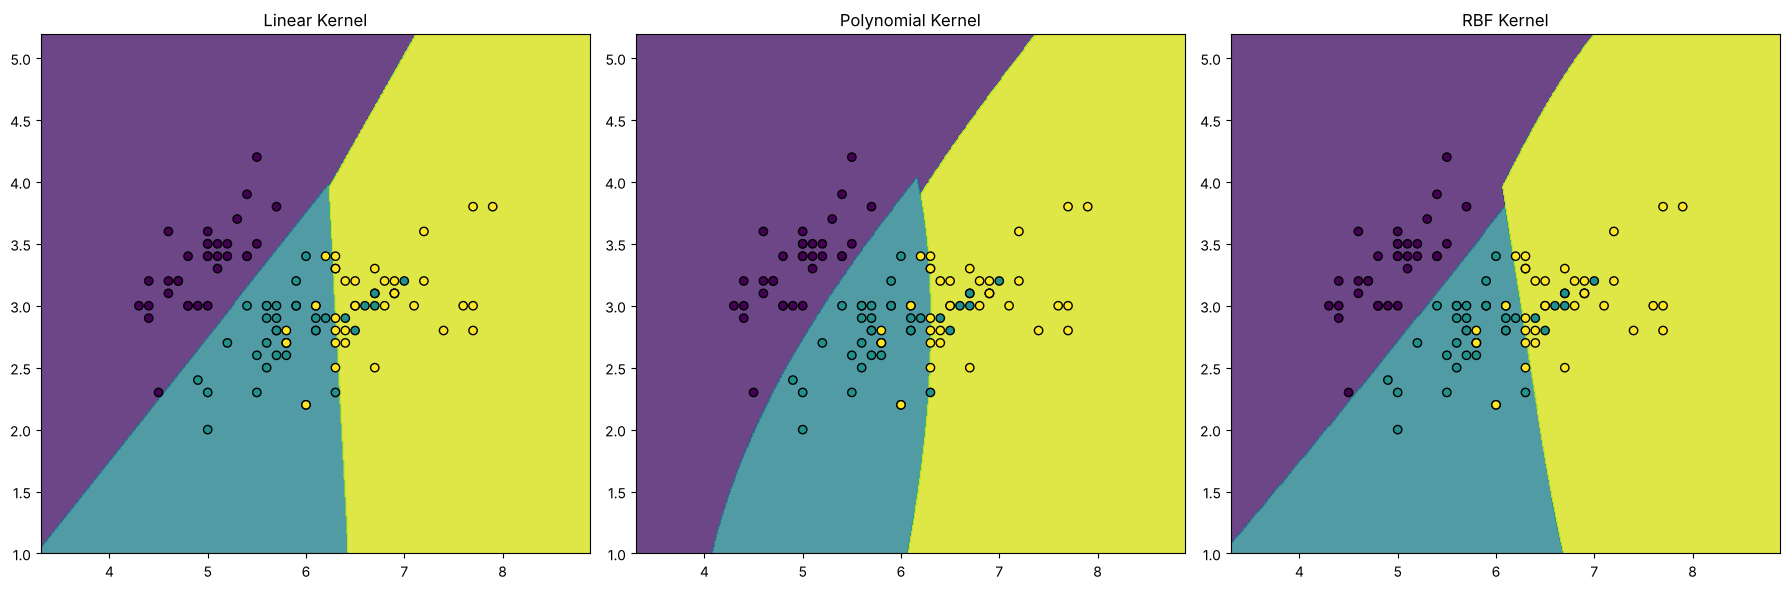

In [7]:
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))

X_train_2d = X_train[:, :2]
svm_linear_2d = SVC(kernel='linear').fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel='poly').fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf').fit(X_train_2d, y_train)

grid = np.c_[xx.ravel(), yy.ravel()]
Z_linear = svm_linear_2d.predict(grid).reshape(xx.shape)
Z_poly = svm_poly_2d.predict(grid).reshape(xx.shape)
Z_rbf = svm_rbf_2d.predict(grid).reshape(xx.shape)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, Z, title in zip(axes, [Z_linear, Z_poly, Z_rbf], ["Linear Kernel", "Polynomial Kernel", "RBF Kernel"]):
    ax.contourf(xx, yy, Z, alpha=0.8)
    ax.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
    ax.set_title(title)
plt.tight_layout()
plt.show()

The linear kernel gives straight boundaries; polynomial and RBF give more flexible, curved ones. Small differences in boundaries can mean large differences in real-world cost.

## 3. Tuning SVM parameters

**Theory.**

* **`C` (regularisation):** trade-off between a wide margin and misclassification. *High `C`* = little tolerance for errors (narrow margin, risk of overfitting); *low `C`* = wider, softer margin.
* **Kernel parameters:** `degree` (polynomial) and `gamma` (RBF: influence of a single training example) shape how data is mapped.
* **Grid search + cross-validation** evaluates *every* combination, scoring each on several folds. It is exhaustive, so more hyperparameters = longer runtime; randomized search is the faster alternative.

In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4],
}
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation Score: {best_score:.2f}")

best_model = SVC(**best_params)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
display(styled_report(y_test, y_pred))

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.99
Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


The result is close to the default models — not a failure of tuning but a reflection of how easy the Iris classification problem is.

**Visualising the effect of `C` (RBF kernel):**

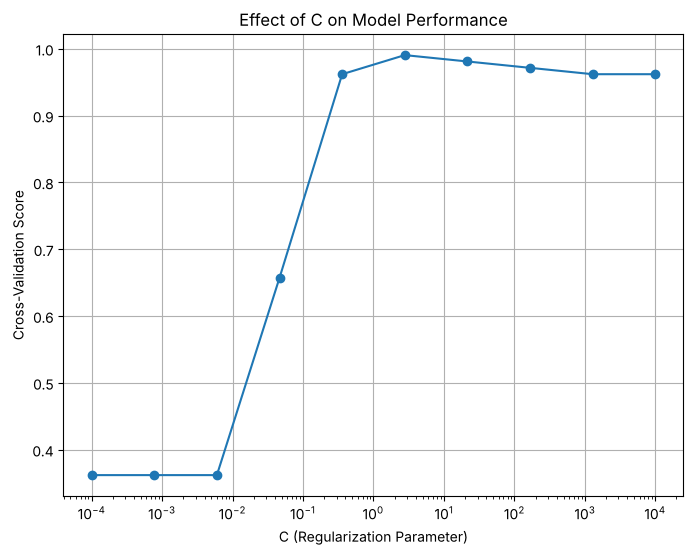

In [9]:
param_grid_c = {'C': np.logspace(-4, 4, 10), 'kernel': ['rbf']}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

plt.figure(figsize=(8, 6))
plt.plot(grid_search_c.param_grid['C'], grid_search_c.cv_results_['mean_test_score'], marker='o')
plt.xscale('log')
plt.xlabel('C (Regularization Parameter)')
plt.ylabel('Cross-Validation Score')
plt.title('Effect of C on Model Performance')
plt.grid(True)
plt.show()

Performance plateaus once `C` is large enough — diminishing returns. Beyond grid search, `RandomizedSearchCV` samples a subset of the parameter space and is more efficient for large spaces.

## 4. SVMs in high-dimensional spaces

**Theory.** SVMs handle **wide** data (many features relative to samples) well, because the decision function depends only on the support vectors and the kernel trick avoids explicit high-dimensional computation. Guidelines:

* **Linear kernel** – suited when the number of features is large.
* **Non-linear kernels (RBF/poly)** – for complex boundaries.
* **Regularisation** (L1/L2, via `C`) helps prevent overfitting by reducing the influence of irrelevant features.
* **PCA** can project the data to 2D for visualisation.

Synthetic data: 1000 samples, 1000 features, only 50 informative.

In [10]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_features=1000, n_informative=50,
                           n_redundant=0, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")
display(styled_report(y_test, y_pred))

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.765,0.765,0.765,162
1,0.725,0.725,0.725,138
accuracy,0.747,0.747,0.747,1
macro avg,0.745,0.745,0.745,300
weighted avg,0.747,0.747,0.747,300


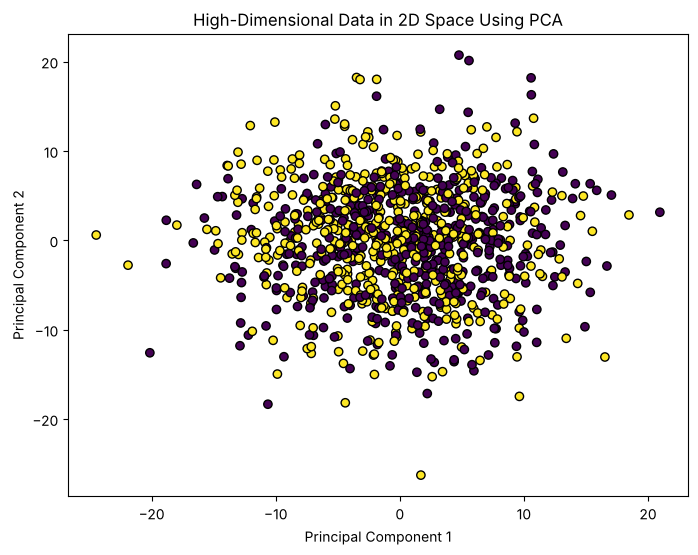

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, edgecolors='k', marker='o')
plt.title("High-Dimensional Data in 2D Space Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In two PCA dimensions the classes overlap heavily — a linear classifier on those two components would struggle. Default arguments on this high-dimensional data are not the strongest; this is where tuning (and regularisation) helps.

In [12]:
# Extra: does tuning help here? (RBF kernel vs linear, scaled features)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC())])
gs = GridSearchCV(pipe, {'svc__kernel': ['linear', 'rbf'], 'svc__C': [0.01, 0.1, 1, 10]}, cv=3, n_jobs=-1)
gs.fit(X_train, y_train)
print("Best:", gs.best_params_, "| CV acc:", round(gs.best_score_, 3), "| test acc:", round(gs.score(X_test, y_test), 3))

Best: {'svc__C': 10, 'svc__kernel': 'rbf'} | CV acc: 0.607 | test acc: 0.66


## 5. Evaluating SVM models

**Theory.** Metrics: accuracy, precision, recall, F1, and the **ROC curve** (true-positive rate vs false-positive rate at all thresholds) with its **AUC**. The dashed diagonal is a model no better than guessing; a good model's curve hugs the upper-left corner. To obtain probabilities for ROC from an `SVC` you must set `probability=True` (it calibrates scores internally, which makes training slower).

Choice of metric depends on the task: if false positives are costly → precision; if missing positives is costly → recall.

In [13]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import roc_curve, auc

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.3, random_state=2024)

svm_model = SVC(kernel='linear', probability=True, random_state=2024)
svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)   # (the book prints this without defining it - defined here)
print(f"Accuracy: {accuracy:.2f}")
display(styled_report(y_test, y_pred))

/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy: 0.95


,precision,recall,f1-score,support
0,0.926,0.940,0.933,67
1,0.961,0.952,0.957,104
accuracy,0.947,0.947,0.947,1
macro avg,0.944,0.946,0.945,171
weighted avg,0.948,0.947,0.947,171


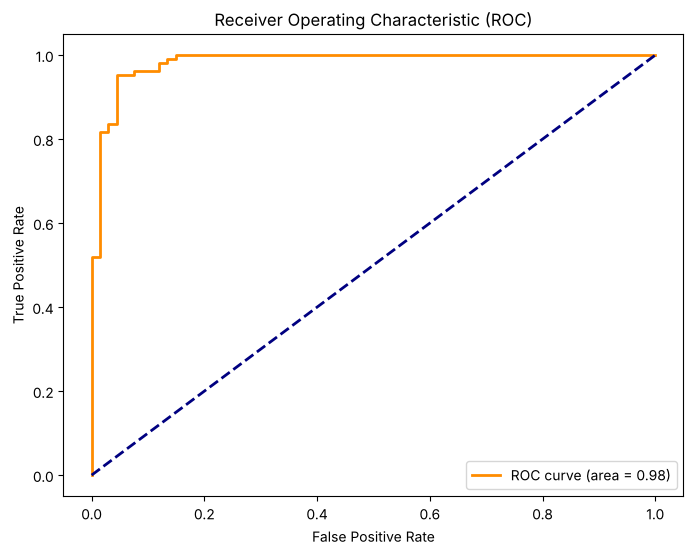

In [14]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

## 6. Practical exercises with SVMs

### Exercise 1 — a simple SVM classifier (Iris)
Steps: load libraries → load data → split → create/train → predict → evaluate.

In [15]:
iris = load_iris()
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(iris.data, iris.target, test_size=0.3, random_state=2024)
clf = SVC(kernel='rbf').fit(Xi_tr, yi_tr)
print("Iris SVC accuracy:", round(accuracy_score(yi_te, clf.predict(Xi_te)), 3))

Iris SVC accuracy: 0.911


### Exercise 2 — tune SVM parameters with grid search (Breast Cancer)

In [16]:
bc = load_breast_cancer()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc.target, test_size=0.3, random_state=2024, stratify=bc.target)

pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC())])
param_grid = {'svc__C': [0.1, 1, 10, 100], 'svc__kernel': ['linear', 'rbf'], 'svc__gamma': ['scale', 0.01, 0.001]}
gs = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1).fit(Xb_tr, yb_tr)

print("Best params:", gs.best_params_)
print("Best CV accuracy:", round(gs.best_score_, 4))
print("Test accuracy:", round(gs.score(Xb_te, yb_te), 4))
print(classification_report(yb_te, gs.predict(Xb_te), target_names=bc.target_names))

Best params: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Best CV accuracy: 0.9799
Test accuracy: 0.9708
              precision    recall  f1-score   support

   malignant       0.97      0.95      0.96        64
      benign       0.97      0.98      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171



### Exercise 3 — visualise SVM decision boundaries on a synthetic dataset

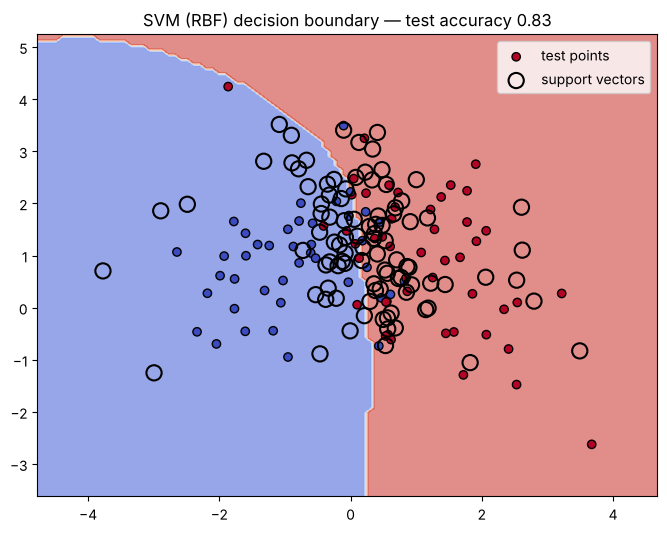

In [17]:
Xs, ys = make_classification(n_samples=300, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, random_state=2024)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=2024)
svm = SVC(kernel='rbf', C=1.0).fit(Xs_tr, ys_tr)

fig, ax = plt.subplots(figsize=(8, 6))
DecisionBoundaryDisplay.from_estimator(svm, Xs, response_method="predict", cmap=plt.cm.coolwarm,
                                       alpha=0.6, ax=ax)
ax.scatter(Xs_te[:, 0], Xs_te[:, 1], c=ys_te, cmap=plt.cm.coolwarm, edgecolors='k', label="test points")
ax.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1], s=120, facecolors='none',
           edgecolors='k', linewidths=1.5, label="support vectors")
ax.set_title(f"SVM (RBF) decision boundary — test accuracy {svm.score(Xs_te, ys_te):.2f}")
ax.legend()
plt.show()

---
### Chapter 7 key takeaways
1. SVMs maximise the **margin** between classes; **support vectors** are the points that define it; **soft margins** (`C`) tolerate errors.
2. **Kernels** (linear, polynomial, RBF) allow non-linear boundaries through the **kernel trick**.
3. Tune `C`, `kernel`, `degree`, `gamma` with cross-validated search; scale features first.
4. SVMs are effective for high-dimensional data; evaluate with precision/recall/F1 and ROC-AUC (`probability=True` for probabilities).